In [1]:
import pandas as pd
import numpy as np

recipes = pd.read_csv(
    r"C:\Users\Rashi\Food_Recipe_Ranking\data\raw\RAW_recipes.csv"
)

interactions = pd.read_csv(
    r"C:\Users\Rashi\Food_Recipe_Ranking\data\raw\RAW_interactions.csv"
)

print("Recipes:", recipes.shape)
print("Interactions:", interactions.shape)

Recipes: (231637, 12)
Interactions: (1132367, 5)


In [2]:
import os

print("Current folder:", os.getcwd())
print("Files and folders:", os.listdir())


Current folder: c:\Users\Rashi\Food_Recipe_Ranking\notebooks
Files and folders: ['01_data_exploration.ipynb']


In [3]:
print("RECIPE COLUMNS:")
print(recipes.columns.tolist())

print("\nINTERACTION COLUMNS:")
print(interactions.columns.tolist())

RECIPE COLUMNS:
['name', 'id', 'minutes', 'contributor_id', 'submitted', 'tags', 'nutrition', 'n_steps', 'steps', 'description', 'ingredients', 'n_ingredients']

INTERACTION COLUMNS:
['user_id', 'recipe_id', 'date', 'rating', 'review']


In [4]:
display(recipes.head())


,name,id,minutes,contributor_id,submitted,tags,nutrition,n_steps,steps,description,ingredients,n_ingredients
0,arriba baked winter squash mexican style,137739,55,47892,2005-09-16,"['60-minutes-or-less', 'time-to-make', 'course...","[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]",11,"['make a choice and proceed with recipe', 'dep...",autumn is my favorite time of year to cook! th...,"['winter squash', 'mexican seasoning', 'mixed ...",7
1,a bit different breakfast pizza,31490,30,26278,2002-06-17,"['30-minutes-or-less', 'time-to-make', 'course...","[173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]",9,"['preheat oven to 425 degrees f', 'press dough...",this recipe calls for the crust to be prebaked...,"['prepared pizza crust', 'sausage patty', 'egg...",6
2,all in the kitchen chili,112140,130,196586,2005-02-25,"['time-to-make', 'course', 'preparation', 'mai...","[269.8, 22.0, 32.0, 48.0, 39.0, 27.0, 5.0]",6,"['brown ground beef in large pot', 'add choppe...",this modified version of 'mom's' chili was a h...,"['ground beef', 'yellow onions', 'diced tomato...",13
3,alouette potatoes,59389,45,68585,2003-04-14,"['60-minutes-or-less', 'time-to-make', 'course...","[368.1, 17.0, 10.0, 2.0, 14.0, 8.0, 20.0]",11,['place potatoes in a large pot of lightly sal...,"this is a super easy, great tasting, make ahea...","['spreadable cheese with garlic and herbs', 'n...",11
4,amish tomato ketchup for canning,44061,190,41706,2002-10-25,"['weeknight', 'time-to-make', 'course', 'main-...","[352.9, 1.0, 337.0, 23.0, 3.0, 0.0, 28.0]",5,['mix all ingredients& boil for 2 1 / 2 hours ...,my dh's amish mother raised him on this recipe...,"['tomato juice', 'apple cider vinegar', 'sugar...",8


In [5]:
display(interactions.head())


,user_id,recipe_id,date,rating,review
0,38094,40893,2003-02-17,4,Great with a salad. Cooked on top of stove for...
1,1293707,40893,2011-12-21,5,"So simple, so delicious! Great for chilly fall..."
2,8937,44394,2002-12-01,4,This worked very well and is EASY. I used not...
3,126440,85009,2010-02-27,5,I made the Mexican topping and took it to bunk...
4,57222,85009,2011-10-01,5,"Made the cheddar bacon topping, adding a sprin..."


In [6]:
print("Missing values in Recipes:")
print(recipes.isnull().sum())

print("\nMissing values in Interactions:")
print(interactions.isnull().sum())

Missing values in Recipes:
name                 1
id                   0
minutes              0
contributor_id       0
submitted            0
tags                 0
nutrition            0
n_steps              0
steps                0
description       4979
ingredients          0
n_ingredients        0
dtype: int64

Missing values in Interactions:
user_id        0
recipe_id      0
date           0
rating         0
review       169
dtype: int64


In [7]:
print(interactions['rating'].value_counts().sort_index())

rating
0     60847
1     12818
2     14123
3     40855
4    187360
5    816364
Name: count, dtype: int64


In [8]:
print("Total zero ratings:", (interactions['rating'] == 0).sum())

print("\nExamples of zero-rated interactions:")
display(interactions[interactions['rating'] == 0].head(10))

Total zero ratings: 60847

Examples of zero-rated interactions:


,user_id,recipe_id,date,rating,review
6,124416,120345,2011-08-06,0,"Just an observation, so I will not rate. I fo..."
12,468945,134728,2008-02-20,0,Made my own buttermilk w/ vinegar and milk. U...
23,681408,225241,2008-03-14,0,This is a very good recipe. We also want to c...
39,2002068522,29093,2018-03-26,0,i made it and it was amazing
56,980899,79222,2010-10-18,0,"I used half cream and half 1% milk, added anot..."
63,1874846,79222,2011-04-04,0,FABULOUS!<br/><br/>I could not afford any of t...
66,1802697284,79222,2014-11-16,0,Awesome chowder! I used both canned and imitat...
67,2002097693,79222,2018-04-05,0,Do you have cook the potatoes beforehand?
119,1232945,487707,2012-10-08,0,Loved this salsa flavored meatloaf...tang is a...
134,2001891832,183729,2018-04-30,0,There is no cooking temp?????? Love this recip...


In [9]:
# Keep only interactions with ratings from 1 to 5
rated_interactions = interactions[interactions['rating'] > 0].copy()

print("Original interactions:", len(interactions))
print("Rated interactions:", len(rated_interactions))
print("Unrated interactions removed:", len(interactions) - len(rated_interactions))

Original interactions: 1132367
Rated interactions: 1071520
Unrated interactions removed: 60847


In [10]:
print("Unique recipes rated:", rated_interactions['recipe_id'].nunique())

print("Unique users:", rated_interactions['user_id'].nunique())

print("Total valid ratings:", len(rated_interactions))

Unique recipes rated: 226590
Unique users: 196098
Total valid ratings: 1071520


In [36]:
overall_mean = np.mean(rated_interactions['rating'])

print("Overall average rating:", round(overall_mean, 3))

Overall average rating: 4.661


In [12]:
recipe_stats = rated_interactions.groupby('recipe_id')['rating'].agg(
    ['mean', 'median', 'count', 'std']
).reset_index()

recipe_stats.columns = [
    'recipe_id', 'average_rating', 'median_rating', 'rating_count', 'rating_std'
]

display(recipe_stats.head())

print("Total recipes with ratings:", len(recipe_stats))

,recipe_id,average_rating,median_rating,rating_count,rating_std
0,38,4.250000,4.0,4,0.500000
1,39,3.000000,3.0,1,NaN
2,40,4.333333,5.0,9,1.322876
3,41,4.500000,4.5,2,0.707107
4,43,1.000000,1.0,1,NaN


Total recipes with ratings: 226590


In [13]:
top_average = recipe_stats.sort_values(
    by='average_rating',
    ascending=False
)

display(top_average.head(10))

,recipe_id,average_rating,median_rating,rating_count,rating_std
226589,537716,5.0,5.0,1,NaN
226588,537485,5.0,5.0,1,NaN
226587,537459,5.0,5.0,1,NaN
226586,537458,5.0,5.0,1,NaN
226583,537242,5.0,5.0,1,NaN
226582,537241,5.0,5.0,1,NaN
226565,536700,5.0,5.0,1,NaN
226564,536696,5.0,5.0,1,NaN
226562,536679,5.0,5.0,1,NaN
226561,536678,5.0,5.0,6,0.0


In [14]:
print(recipe_stats['rating_count'].describe())

count    226590.000000
mean          4.728894
std          16.582369
min           1.000000
25%           1.000000
50%           2.000000
75%           4.000000
max        1496.000000
Name: rating_count, dtype: float64


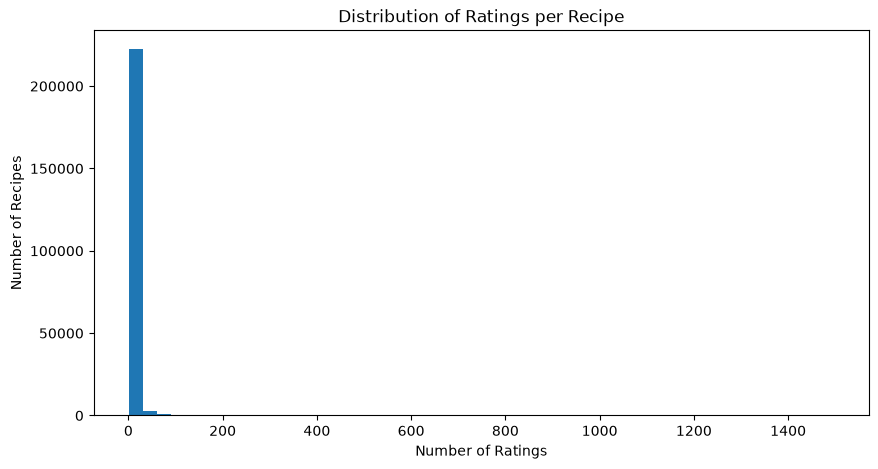

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(recipe_stats['rating_count'], bins=50)

plt.title('Distribution of Ratings per Recipe')
plt.xlabel('Number of Ratings')
plt.ylabel('Number of Recipes')

plt.show()

In [16]:
print("Recipes with only 1 rating:",
      (recipe_stats['rating_count'] == 1).sum())

print("Recipes with 5 or fewer ratings:",
      (recipe_stats['rating_count'] <= 5).sum())

print("Recipes with 10 or more ratings:",
      (recipe_stats['rating_count'] >= 10).sum())

print("Recipes with 50 or more ratings:",
      (recipe_stats['rating_count'] >= 50).sum())

Recipes with only 1 rating: 91698
Recipes with 5 or fewer ratings: 185993
Recipes with 10 or more ratings: 20060
Recipes with 50 or more ratings: 1979


In [17]:
thresholds = [5, 10, 20]

for threshold in thresholds:
    filtered = recipe_stats[
        recipe_stats['rating_count'] >= threshold
    ]

    print(
        f"Minimum {threshold} ratings: "
        f"{len(filtered)} recipes"
    )

Minimum 5 ratings: 50978 recipes
Minimum 10 ratings: 20060 recipes
Minimum 20 ratings: 7400 recipes


In [18]:
# Keep recipes with at least 10 ratings
filtered_recipes = recipe_stats[
    recipe_stats['rating_count'] >= 10
].copy()

print("Recipes available for ranking:", len(filtered_recipes))

Recipes available for ranking: 20060


In [19]:
# Calculate the minimum rating count parameter
m = 10

# Overall average rating
C = overall_mean

print("Minimum rating count (m):", m)
print("Overall average rating (C):", round(C, 3))

Minimum rating count (m): 10
Overall average rating (C): 4.661


In [20]:
# Calculate Bayesian Weighted Average
filtered_recipes['bayesian_rating'] = (
    (filtered_recipes['rating_count'] /
     (filtered_recipes['rating_count'] + m))
    * filtered_recipes['average_rating']
    +
    (m / (filtered_recipes['rating_count'] + m))
    * C
)

display(
    filtered_recipes.sort_values(
        'bayesian_rating',
        ascending=False
    ).head(10)
)

,recipe_id,average_rating,median_rating,rating_count,rating_std,bayesian_rating
220058,486496,5.000000,5.0,192,0.000000,4.983243
220002,486261,4.990783,5.0,217,0.095781,4.976277
217036,474520,5.000000,5.0,95,0.000000,4.967762
225307,515167,5.000000,5.0,73,0.000000,4.959217
87363,154351,5.000000,5.0,69,0.000000,4.957152
103499,186029,5.000000,5.0,67,0.000000,4.956039
25420,46262,4.971429,5.0,175,0.167077,4.954676
221675,495275,5.000000,5.0,64,0.000000,4.954257
43751,77497,4.987654,5.0,81,0.111111,4.951813
42260,74805,4.987179,5.0,78,0.113228,4.950170


In [21]:
display(
    filtered_recipes[
        ['recipe_id', 'average_rating', 'rating_count', 'rating_std', 'bayesian_rating']
    ].sort_values(
        'bayesian_rating', ascending=False
    ).head(10).round(3)
)

,recipe_id,average_rating,rating_count,rating_std,bayesian_rating
220058,486496,5.000,192,0.000,4.983
220002,486261,4.991,217,0.096,4.976
217036,474520,5.000,95,0.000,4.968
225307,515167,5.000,73,0.000,4.959
87363,154351,5.000,69,0.000,4.957
103499,186029,5.000,67,0.000,4.956
25420,46262,4.971,175,0.167,4.955
221675,495275,5.000,64,0.000,4.954
43751,77497,4.988,81,0.111,4.952
42260,74805,4.987,78,0.113,4.950


In [22]:
print(filtered_recipes.loc[
    filtered_recipes['recipe_id'] == 220058,
    ['recipe_id', 'average_rating', 'rating_count',
     'rating_std', 'bayesian_rating']
].to_string(index=False))

Empty DataFrame
Columns: [recipe_id, average_rating, rating_count, rating_std, bayesian_rating]
Index: []


In [23]:
print(filtered_recipes.head().to_string(index=False))

 recipe_id  average_rating  median_rating  rating_count  rating_std  bayesian_rating
        49        4.833333            5.0            18    0.383482         4.771964
        62        4.681818            5.0            22    0.567900         4.675468
        66        4.947368            5.0            19    0.229416         4.848793
       142        4.681818            5.0            22    0.716231         4.675468
       150        4.583333            5.0            12    0.996205         4.618863


In [24]:
filtered_recipes['average_rank'] = (
    filtered_recipes['average_rating']
    .rank(method='min', ascending=False)
)

filtered_recipes['bayesian_rank'] = (
    filtered_recipes['bayesian_rating']
    .rank(method='min', ascending=False)
)

display(
    filtered_recipes[
        ['recipe_id', 'average_rating', 'rating_count',
         'average_rank', 'bayesian_rating', 'bayesian_rank']
    ].sort_values('bayesian_rank').head(10)
)

,recipe_id,average_rating,rating_count,average_rank,bayesian_rating,bayesian_rank
220058,486496,5.000000,192,1.0,4.983243,1.0
220002,486261,4.990783,217,1773.0,4.976277,2.0
217036,474520,5.000000,95,1.0,4.967762,3.0
225307,515167,5.000000,73,1.0,4.959217,4.0
87363,154351,5.000000,69,1.0,4.957152,5.0
103499,186029,5.000000,67,1.0,4.956039,6.0
25420,46262,4.971429,175,1808.0,4.954676,7.0
221675,495275,5.000000,64,1.0,4.954257,8.0
43751,77497,4.987654,81,1774.0,4.951813,9.0
42260,74805,4.987179,78,1775.0,4.950170,10.0


In [25]:
print(
    filtered_recipes[
        ['recipe_id', 'average_rating', 'rating_count',
         'average_rank', 'bayesian_rating', 'bayesian_rank']
    ]
    .sort_values('bayesian_rank')
    .head(10)
    .to_string(index=False)
)

 recipe_id  average_rating  rating_count  average_rank  bayesian_rating  bayesian_rank
    486496        5.000000           192           1.0         4.983243            1.0
    486261        4.990783           217        1773.0         4.976277            2.0
    474520        5.000000            95           1.0         4.967762            3.0
    515167        5.000000            73           1.0         4.959217            4.0
    154351        5.000000            69           1.0         4.957152            5.0
    186029        5.000000            67           1.0         4.956039            6.0
     46262        4.971429           175        1808.0         4.954676            7.0
    495275        5.000000            64           1.0         4.954257            8.0
     77497        4.987654            81        1774.0         4.951813            9.0
     74805        4.987179            78        1775.0         4.950170           10.0


In [26]:
top_average = filtered_recipes.sort_values(
    'average_rating', ascending=False
).head(10)

top_bayesian = filtered_recipes.sort_values(
    'bayesian_rating', ascending=False
).head(10)

print("Top 10 recipes by Average Rating:")
display(top_average[['recipe_id', 'average_rating', 'rating_count']])

print("Top 10 recipes by Bayesian Rating:")
display(top_bayesian[['recipe_id', 'bayesian_rating', 'rating_count']])

Top 10 recipes by Average Rating:


,recipe_id,average_rating,rating_count
226035,524960,5.0,11
171,356,5.0,16
226043,524984,5.0,12
85116,150028,5.0,10
225645,518190,5.0,10
225637,518151,5.0,28
225634,518145,5.0,24
225633,518143,5.0,13
225626,518113,5.0,10
177932,353023,5.0,10


Top 10 recipes by Bayesian Rating:


,recipe_id,bayesian_rating,rating_count
220058,486496,4.983243,192
220002,486261,4.976277,217
217036,474520,4.967762,95
225307,515167,4.959217,73
87363,154351,4.957152,69
103499,186029,4.956039,67
25420,46262,4.954676,175
221675,495275,4.954257,64
43751,77497,4.951813,81
42260,74805,4.950170,78


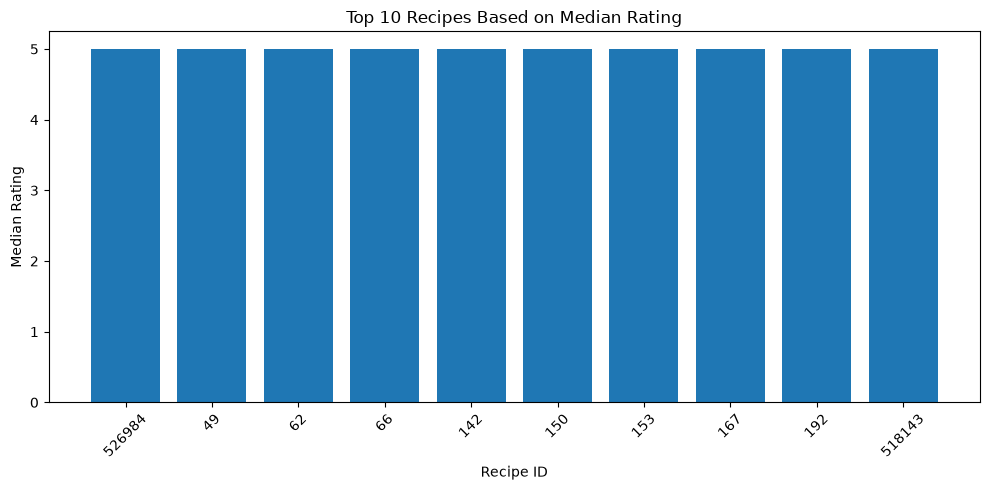

In [27]:
top_median = filtered_recipes.sort_values(
    by='median_rating',
    ascending=False
).head(10)

plt.figure(figsize=(10, 5))

plt.bar(
    top_median['recipe_id'].astype(str),
    top_median['median_rating']
)

plt.title('Top 10 Recipes Based on Median Rating')
plt.xlabel('Recipe ID')
plt.ylabel('Median Rating')
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    r"C:\Users\Rashi\Food_Recipe_Ranking\outputs\figures\median_top10.png",
    dpi=300
)

plt.show()

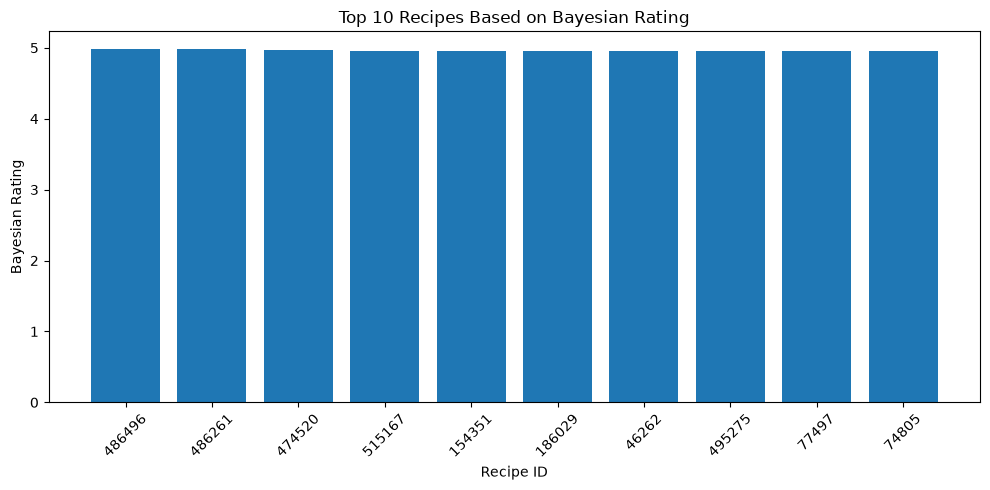

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    top_bayesian['recipe_id'].astype(str),
    top_bayesian['bayesian_rating']
)

plt.title('Top 10 Recipes Based on Bayesian Rating')
plt.xlabel('Recipe ID')
plt.ylabel('Bayesian Rating')
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    r"C:\Users\Rashi\Food_Recipe_Ranking\outputs\figures\bayesian_top10.png",
    dpi=300
)

plt.show()

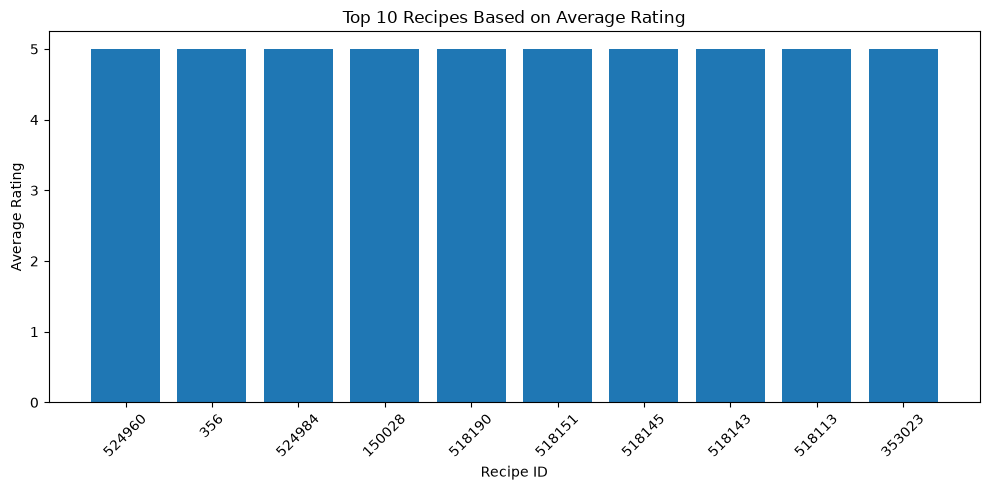

In [29]:
plt.figure(figsize=(10, 5))

plt.bar(
    top_average['recipe_id'].astype(str),
    top_average['average_rating']
)

plt.title('Top 10 Recipes Based on Average Rating')
plt.xlabel('Recipe ID')
plt.ylabel('Average Rating')
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    r"C:\Users\Rashi\Food_Recipe_Ranking\outputs\figures\average_top10.png",
    dpi=300
)

plt.show()

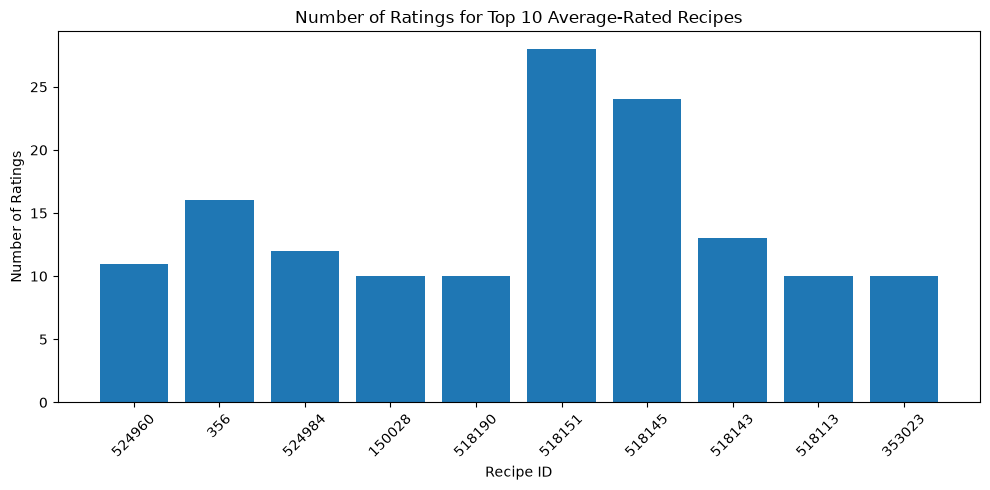

In [30]:
plt.figure(figsize=(10, 5))

plt.bar(
    top_average['recipe_id'].astype(str),
    top_average['rating_count']
)

plt.title('Number of Ratings for Top 10 Average-Rated Recipes')
plt.xlabel('Recipe ID')
plt.ylabel('Number of Ratings')
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    r"C:\Users\Rashi\Food_Recipe_Ranking\outputs\figures\average_rating_counts.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

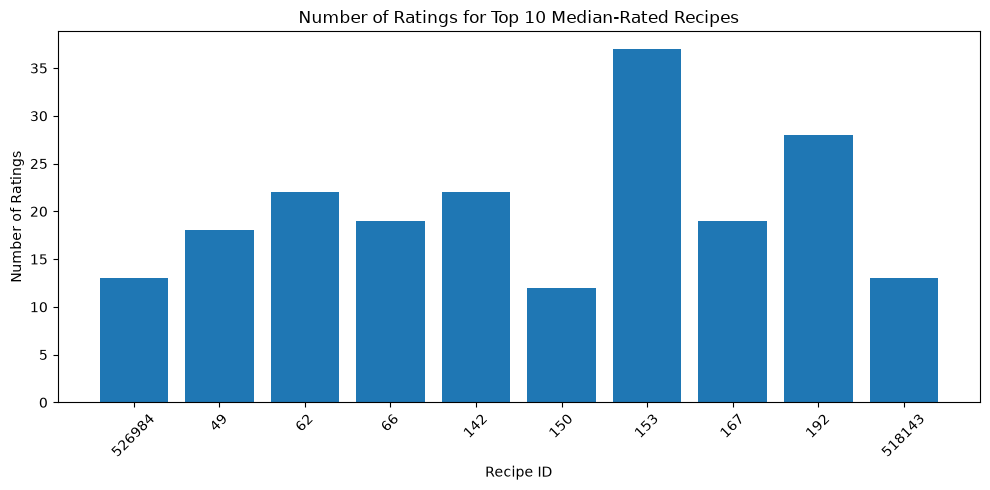

In [31]:
plt.figure(figsize=(10, 5))

plt.bar(
    top_median['recipe_id'].astype(str),
    top_median['rating_count']
)

plt.title('Number of Ratings for Top 10 Median-Rated Recipes')
plt.xlabel('Recipe ID')
plt.ylabel('Number of Ratings')
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    r"C:\Users\Rashi\Food_Recipe_Ranking\outputs\figures\median_rating_counts.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

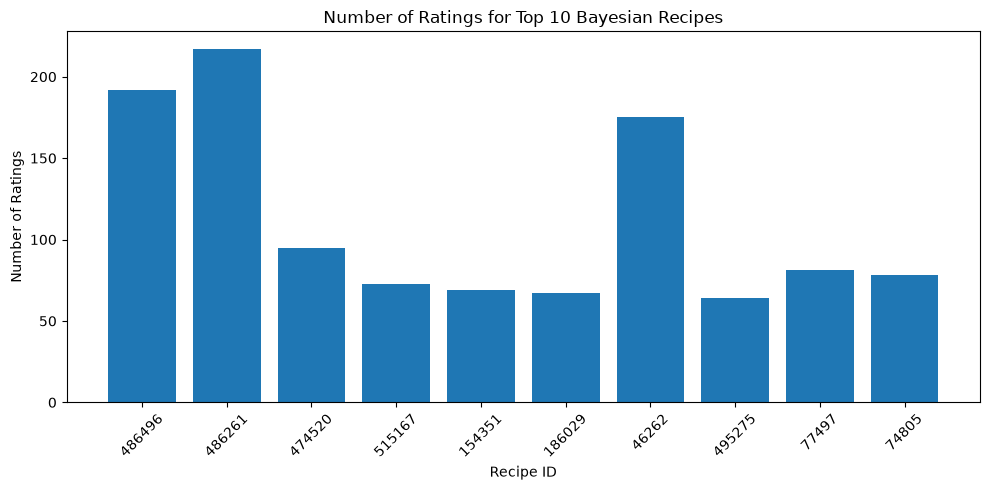

In [32]:
plt.figure(figsize=(10, 5))

plt.bar(
    top_bayesian['recipe_id'].astype(str),
    top_bayesian['rating_count']
)

plt.title('Number of Ratings for Top 10 Bayesian Recipes')
plt.xlabel('Recipe ID')
plt.ylabel('Number of Ratings')
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    r"C:\Users\Rashi\Food_Recipe_Ranking\outputs\figures\bayesian_rating_counts.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [33]:
filtered_recipes.sort_values(
    'bayesian_rating',
    ascending=False
).to_csv(
    r"C:\Users\Rashi\Food_Recipe_Ranking\outputs\rankings\recipe_rankings.csv",
    index=False
)

print("Recipe rankings saved successfully!")

Recipe rankings saved successfully!


In [34]:
import os

folder = r"C:\Users\Rashi\Food_Recipe_Ranking\outputs\figures"

print("Folder exists:", os.path.exists(folder))
print("Files inside folder:", os.listdir(folder))

Folder exists: True
Files inside folder: ['average_rating_counts.png', 'average_top10.png', 'bayesian_rating_counts.png', 'bayesian_top10.png', 'median_rating_counts.png', 'median_top10.png', 'rating_distributions.png']


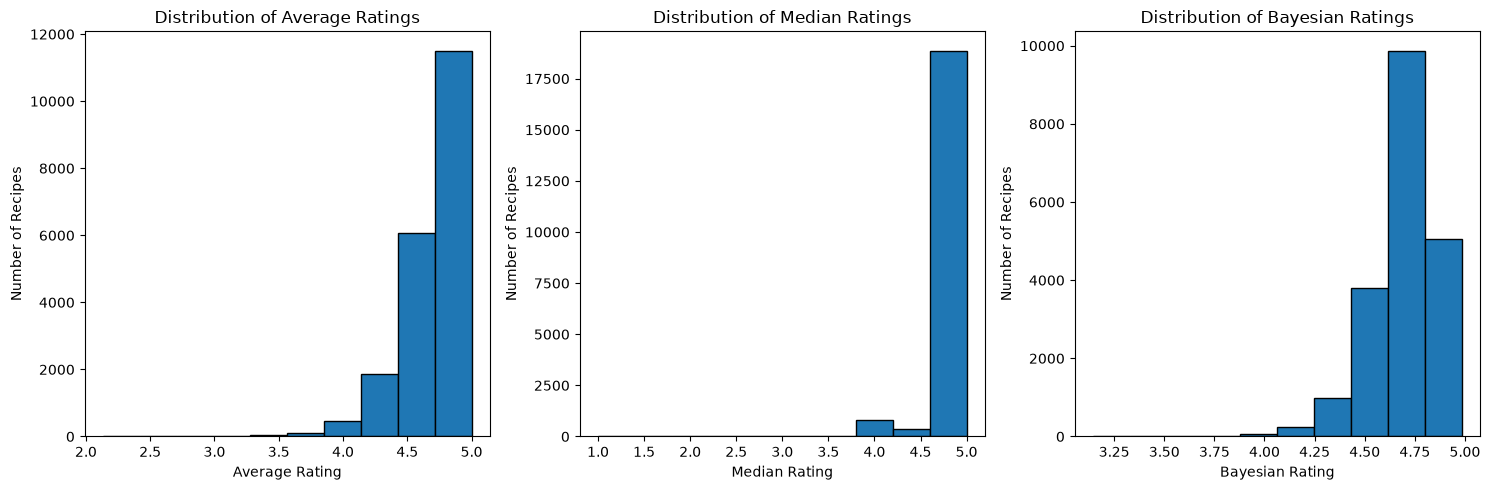

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

# 1. Average Rating Distribution
plt.subplot(1, 3, 1)

plt.hist(filtered_recipes['average_rating'], bins=10, edgecolor='black')

plt.title('Distribution of Average Ratings')
plt.xlabel('Average Rating')
plt.ylabel('Number of Recipes')


# 2. Median Rating Distribution
plt.subplot(1, 3, 2)

plt.hist(filtered_recipes['median_rating'], bins=10, edgecolor='black')

plt.title('Distribution of Median Ratings')
plt.xlabel('Median Rating')
plt.ylabel('Number of Recipes')


# 3. Bayesian Rating Distribution
plt.subplot(1, 3, 3)

plt.hist(filtered_recipes['bayesian_rating'], bins=10, edgecolor='black')

plt.title('Distribution of Bayesian Ratings')
plt.xlabel('Bayesian Rating')
plt.ylabel('Number of Recipes')


plt.tight_layout()

plt.savefig(
    r"C:\Users\Rashi\Food_Recipe_Ranking\outputs\figures\rating_distributions.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [37]:
import scipy
print("SciPy version:", scipy.__version__)

SciPy version: 1.18.1


In [38]:
from scipy import stats
import numpy as np

ratings = rated_interactions["rating"]

sample_size = len(ratings)
standard_error = stats.sem(ratings)

confidence_interval = stats.t.interval(
    confidence=0.95,
    df=sample_size - 1,
    loc=np.mean(ratings),
    scale=standard_error
)

print("Overall average rating:", round(np.mean(ratings), 3))
print("95% Confidence Interval:", confidence_interval)

Overall average rating: 4.661
95% Confidence Interval: (np.float64(4.660129570314055), np.float64(4.662867667255005))
